In [1]:
import time, hashlib, warnings, json
T0=time.time()
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV
from sklearn.metrics import f1_score, confusion_matrix, roc_auc_score
from feature_helper import extract_features
SEED=42; LABELS=[0,1,2,3,4]; NAMES=['숲','경작지','초본','목초지','하천']
Path('cache').mkdir(exist_ok=True)
tr=pd.read_csv('data/train.csv',encoding='utf-8-sig'); te=pd.read_csv('data/test.csv',encoding='utf-8-sig')
ss=pd.read_csv('data/sample_submission.csv',encoding='utf-8-sig')
assert len(tr)==750 and len(te)==250
y=tr.label.values
def el(): print(f'[elapsed {time.time()-T0:.0f}s]')

In [2]:
# EDA
print('결측',tr.isna().sum().sum(),te.isna().sum().sum(),'| ID중복',tr.image_id.duplicated().sum(),te.image_id.duplicated().sum(),'| ID겹침',len(set(tr.image_id)&set(te.image_id)))
print('라벨 분포',tr.label.value_counts().sort_index().to_dict())
def load(p): 
    with Image.open(p) as im: return np.asarray(im.convert('RGB'))
Xtr_img=np.stack([load(p) for p in tr.image_path]); Xte_img=np.stack([load(p) for p in te.image_path])
print('shape',Xtr_img.shape,Xte_img.shape)
md5=lambda p: hashlib.md5(open(p,'rb').read()).hexdigest()
m1=set(map(md5,tr.image_path)); m2=set(map(md5,te.image_path)); print('MD5 train-test 겹침',len(m1&m2))
def color_stats(X):
    a=X.astype(np.float32); g=a.mean(-1)
    return np.c_[a[...,0].mean((1,2)),a[...,1].mean((1,2)),a[...,2].mean((1,2)),g.mean((1,2)),a.std((1,2,3)),
                 (2*a[...,1]-a[...,0]-a[...,2]).mean((1,2)),np.abs(np.diff(g,axis=1)).mean((1,2))+np.abs(np.diff(g,axis=2)).mean((1,2))]
CS_tr=color_stats(Xtr_img)
print(pd.DataFrame(CS_tr,columns=['R','G','B','bright','std','exg','edge']).groupby(y).mean().round(1)); el()

결측 0 0 | ID중복 0 0 | ID겹침 0
라벨 분포 {0: 150, 1: 150, 2: 150, 3: 150, 4: 150}
shape (750, 64, 64, 3) (250, 64, 64, 3)
MD5 train-test 겹침 0


            R           G           B      bright        std   exg  edge
0   39.299999   64.199997   76.099998   59.900002  16.100000  13.1   3.8
1  127.900002  119.500000  117.000000  121.500000  30.100000  -6.0   6.8
2  101.699997  101.900002  107.199997  103.599998  19.000000  -5.2  11.1
3   61.500000   88.400002   93.199997   81.000000  18.700001  22.0   5.5
4   68.500000   87.599998   98.099998   84.699997  24.200001   8.7   8.8
[elapsed 1s]


In [3]:
# 평가 도구
rcv=RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED); FOLDS=list(rcv.split(np.zeros(len(y)),y))
cv3=list(StratifiedKFold(3,shuffle=True,random_state=SEED).split(np.zeros(len(y)),y))
mf1=lambda a,b: f1_score(a,b,labels=LABELS,average='macro',zero_division=0)
LOG=[]
def lr_model(): return GridSearchCV(make_pipeline(StandardScaler(),LogisticRegression(max_iter=5000)),{'logisticregression__C':[0.01,0.1,1]},cv=3,scoring='f1_macro',n_jobs=8)
def svc_model(): return GridSearchCV(make_pipeline(StandardScaler(),SVC(kernel='rbf',probability=True,random_state=SEED)),{'svc__C':[1,10]},cv=3,scoring='f1_macro',n_jobs=8)
def run_cv(make,X,folds,proba=False):
    fs=[]; pred=np.zeros((len(folds)//(len(folds) if len(folds)==3 else 5),len(y)),int) if False else None
    oof_rep={}; P={}
    for i,(a,b) in enumerate(folds):
        m=make().fit(X[a],y[a]); p=m.predict(X[b]); fs.append(mf1(y[b],p))
        r=i//(3 if len(folds)==3 else 5); oof_rep.setdefault(r,np.zeros(len(y),int))[b]=p
        if proba: P.setdefault(r,np.zeros((len(y),5)))[b]=m.predict_proba(X[b])
    pooled=[mf1(y,o) for o in oof_rep.values()]
    return dict(folds=np.array(fs),pooled=np.array(pooled),oof=oof_rep[0],proba=P.get(0))
def report(stage,name,res,ref=None,evaln='5x3'):
    pc=f1_score(y,res['oof'],labels=LABELS,average=None)
    d=(res['folds']-ref['folds']) if ref is not None else None
    row=dict(stage=stage,cand=name,eval=evaln,mean=res['pooled'].mean().round(4),std=res['pooled'].std().round(4),river=pc[4].round(3),
             delta=None if d is None else round(d.mean(),4),wins=None if d is None else f'{(d>0).sum()}/{len(d)}',perclass=pc.round(3).tolist())
    LOG.append(row); print(row); return row

In [4]:
# 원본 특징
F_tr=extract_features(tr.image_path,cache_path='cache/feat_orig_train.npz',verbose=False)
F_te=extract_features(te.image_path,cache_path='cache/feat_orig_test.npz',verbose=False)
print(F_tr.shape,F_te.shape,np.isfinite(F_tr).all()); el()

2026-10-01 17:19:56.914439275 [W:onnxruntime:Default, device_discovery.cc:164 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:89 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


(750, 1280) (250, 1280) True
[elapsed 7s]


In [5]:
# 1단계
R0=run_cv(lambda: make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),CS_tr,FOLDS); report(1,'B0 color+LR',R0)
R1=run_cv(lr_model,F_tr,FOLDS); report(1,'B1 feat+LR',R1,R0)
R2=run_cv(svc_model,F_tr,FOLDS); r2=report(1,'B2 feat+SVC',R2,R1)
d=R2['folds']-R1['folds']; best1,Rb,mk1=( ('B2',R2,svc_model) if d.mean()>=0.005 and (d>0).sum()>=10 else ('B1',R1,lr_model))
print('1단계 채택',best1)
m=lr_model().fit(F_tr,y); sub=pd.DataFrame({'image_id':te.image_id,'label':m.predict(F_te)}); sub.to_csv('submission.csv',index=False,encoding='utf-8-sig'); print('안전 제출본 저장')
T=max(0.005,Rb['pooled'].std()); print('T =',round(T,4))
print(pd.DataFrame(confusion_matrix(y,Rb['oof']),index=NAMES,columns=NAMES))
for c in (3,2):
    msk=np.isin(y,[4,c]); fa=[]
    for a,b in StratifiedKFold(5,shuffle=True,random_state=SEED).split(F_tr[msk],y[msk]):
        mm=make_pipeline(StandardScaler(),LogisticRegression(C=0.1,max_iter=5000)).fit(F_tr[msk][a],y[msk][a]==4); fa.append(roc_auc_score(y[msk][b]==4,mm.decision_function(F_tr[msk][b])))
    print(f'하천 vs {NAMES[c]} 이진 AUC {np.mean(fa):.3f}')
el()

{'stage': 1, 'cand': 'B0 color+LR', 'eval': '5x3', 'mean': 0.7768, 'std': 0.004, 'river': 0.613, 'delta': None, 'wins': None, 'perclass': [0.865, 0.871, 0.807, 0.729, 0.613]}


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/usr/lib/python3/dist-packages/scipy

{'stage': 1, 'cand': 'B1 feat+LR', 'eval': '5x3', 'mean': 0.9568, 'std': 0.0012, 'river': 0.932, 'delta': 0.1814, 'wins': '15/15', 'perclass': [0.961, 0.963, 0.977, 0.947, 0.932]}


{'stage': 1, 'cand': 'B2 feat+SVC', 'eval': '5x3', 'mean': 0.939, 'std': 0.0011, 'river': 0.894, 'delta': -0.0177, 'wins': '2/15', 'perclass': [0.974, 0.948, 0.949, 0.924, 0.894]}
1단계 채택 B1


안전 제출본 저장
T = 0.005
       숲  경작지   초본  목초지   하천
숲    147    0    1    1    1
경작지    1  143    0    2    4
초본     4    0  146    0    0
목초지    2    0    2  144    2
하천     2    4    0    7  137
하천 vs 목초지 이진 AUC 0.998


하천 vs 초본 이진 AUC 1.000
[elapsed 51s]


예측: ['목초지', '경작지', '목초지', '숲', '목초지', '목초지', '목초지', '경작지', '목초지', '숲', '목초지', '경작지', '경작지']


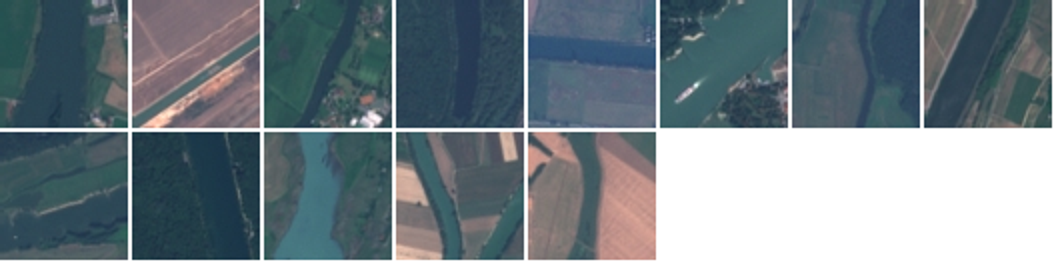

In [6]:
# 하천 오분류 몽타주
from IPython.display import display
bad=np.where((y==4)&(Rb['oof']!=4))[0][:24]
if len(bad):
    W=Image.new('RGB',(8*66,((len(bad)-1)//8+1)*66),'white')
    for k,i in enumerate(bad): W.paste(Image.fromarray(Xtr_img[i]),((k%8)*66,(k//8)*66))
    print('예측:',[NAMES[p] for p in Rb['oof'][bad]]); display(W.resize((W.width*2,W.height*2)))

In [7]:
# 2단계: 8방향 평균 특징
OPS=[None,Image.Transpose.FLIP_LEFT_RIGHT,Image.Transpose.FLIP_TOP_BOTTOM,Image.Transpose.ROTATE_90,Image.Transpose.ROTATE_180,Image.Transpose.ROTATE_270,Image.Transpose.TRANSPOSE,Image.Transpose.TRANSVERSE]
def d8(df,tag):
    fs=[]
    for k,op in enumerate(OPS):
        if op is None: paths=list(df.image_path)
        else:
            dd=Path(f'cache/views/{k}'); dd.mkdir(parents=True,exist_ok=True); paths=[]
            for iid,p in zip(df.image_id,df.image_path):
                q=dd/f'{iid}.png'
                if not q.exists():
                    with Image.open(p) as im: im.convert('RGB').transpose(op).save(q)
                paths.append(q)
        fs.append(extract_features(paths,cache_path=f'cache/feat_{tag}_v{k}.npz',verbose=False))
    return np.mean(fs,0),fs[0]
D_tr,id_tr=d8(tr,'train'); D_te,_=d8(te,'test')
assert np.allclose(id_tr,F_tr)
q=np.asarray(Image.open(f'cache/views/3/{tr.image_id[0]}.png')); assert (q==np.asarray(Image.fromarray(Xtr_img[0]).transpose(OPS[3]))).all()
RS2=run_cv(mk1,D_tr,FOLDS); report(2,f'S2 {best1}+D8',RS2,Rb)
d=RS2['folds']-Rb['folds']
if d.mean()>=T and (d>0).sum()>=10: FEATX,FEATXt,Rb,best2=D_tr,D_te,RS2,best1+'+D8'
else: FEATX,FEATXt,best2=F_tr,F_te,best1
print('2단계 채택',best2); el()

{'stage': 2, 'cand': 'S2 B1+D8', 'eval': '5x3', 'mean': 0.9564, 'std': 0.0013, 'river': 0.939, 'delta': -0.0005, 'wins': '9/15', 'perclass': [0.964, 0.96, 0.97, 0.954, 0.939]}
2단계 채택 B1
[elapsed 126s]


In [8]:
# 3단계: ResNet18 fine-tuning (입력 64, 시간 제약으로 PLAN 후퇴 규칙 적용)
import torch, torch.nn as nn, torchvision
torch.set_num_threads(8)
MEAN=torch.tensor([.485,.456,.406]).view(1,3,1,1); STD=torch.tensor([.229,.224,.225]).view(1,3,1,1)
Xt_all=(torch.tensor(Xtr_img).permute(0,3,1,2).float()/255-MEAN)/STD; Xte_t=(torch.tensor(Xte_img).permute(0,3,1,2).float()/255-MEAN)/STD
RES=64; EP=12
def aug(x):
    k=np.random.randint(4); x=torch.rot90(x,k,(2,3))
    return torch.flip(x,(3,)) if np.random.rand()<.5 else x
def tta(m,X):
    m.eval(); out=0
    with torch.no_grad():
        for k in range(4):
            for f in (False,True):
                x=torch.rot90(X,k,(2,3)); x=torch.flip(x,(3,)) if f else x
                if RES!=64: x=nn.functional.interpolate(x,size=RES,mode='bilinear')
                out=out+torch.softmax(m(x),1)
    return (out/8).numpy()
def train_ft(idx,val=None):
    torch.manual_seed(SEED); np.random.seed(SEED)
    m=torchvision.models.resnet18(weights='IMAGENET1K_V1'); m.fc=nn.Linear(512,5)
    opt=torch.optim.AdamW(m.parameters(),3e-4,weight_decay=1e-4); sch=torch.optim.lr_scheduler.CosineAnnealingLR(opt,EP)
    X=Xt_all[idx]; Y=torch.tensor(y[idx]); hist=[]
    for ep in range(EP):
        m.train(); perm=torch.randperm(len(idx)); t=time.time()
        for s in range(0,len(idx),32):
            b=perm[s:s+32]; x=aug(X[b])
            if RES!=64: x=nn.functional.interpolate(x,size=RES,mode='bilinear')
            opt.zero_grad(); nn.functional.cross_entropy(m(x),Y[b]).backward(); opt.step()
        sch.step()
        if val is not None and ep in (3,7,EP-1): hist.append((ep+1,round(mf1(y[val],tta(m,Xt_all[val]).argmax(1)),4)))
        if ep==0: print(f'epoch time {time.time()-t:.1f}s')
    return m,hist
FT_folds=[]; FT_P=np.zeros((len(y),5))
for a,b in cv3:
    assert len(set(a)&set(b))==0
    m,h=train_ft(a,b); P=tta(m,Xt_all[b]); FT_P[b]=P; FT_folds.append(mf1(y[b],P.argmax(1))); print('fold',h); el()
RF=dict(folds=np.array(FT_folds),pooled=np.array([mf1(y,FT_P.argmax(1))]),oof=FT_P.argmax(1))
RB3=run_cv(mk1 if best1=='B1' else svc_model,FEATX,cv3,proba=True); RB3['proba']=RB3['proba']
report(3,f'{best2} (3-fold)',RB3,None,'3fold')
report(3,'FT resnet18@64',RF,RB3,'3fold')
EN_P=(FT_P+RB3['proba'])/2; RE=dict(folds=np.array([mf1(y[b],EN_P[b].argmax(1)) for a,b in cv3]),pooled=np.array([mf1(y,EN_P.argmax(1))]),oof=EN_P.argmax(1))
report(3,'ENS FT+feat (avg prob)',RE,RB3,'3fold'); el()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/akswosla/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


0.3%

0.6%

0.8%

1.1%

...

epoch time 4.3s


fold [(4, 0.9195), (8, 0.9352), (12, 0.9358)]
[elapsed 354s]


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/usr/lib/python3/dist-packages/scipy

{'stage': 3, 'cand': 'B1 (3-fold)', 'eval': '3fold', 'mean': 0.9493, 'std': 0.0, 'river': 0.922, 'delta': None, 'wins': None, 'perclass': [0.957, 0.959, 0.97, 0.937, 0.922]}
{'stage': 3, 'cand': 'FT resnet18@64', 'eval': '3fold', 'mean': 0.9587, 'std': 0.0, 'river': 0.963, 'delta': 0.0093, 'wins': '2/3', 'perclass': [0.964, 0.973, 0.947, 0.947, 0.963]}
{'stage': 3, 'cand': 'ENS FT+feat (avg prob)', 'eval': '3fold', 'mean': 0.9707, 'std': 0.0, 'river': 0.98, 'delta': 0.0214, 'wins': '3/3', 'perclass': [0.964, 0.977, 0.966, 0.967, 0.98]}
[elapsed 391s]


In [9]:
# 최종 선택과 학습
cands={'feat':RB3,'ft':RF,'ens':RE}
def ok(r): d=r['folds']-RB3['folds']; return d.mean()>=T and (d>0).all()
choice='feat'
if ok(RF): choice='ft'
if ok(RE) and (choice=='feat' or RE['folds'].mean()-RF['folds'].mean()>=T and (RE['folds']>RF['folds']).all()): choice='ens'
print('최종 선택',choice)
mfeat=(lr_model() if best1=='B1' else svc_model()).fit(FEATX,y)
if choice=='feat': pred=mfeat.predict(FEATXt)
else:
    mft,_=train_ft(np.arange(len(y))); Pt=tta(mft,Xte_t)
    pred=Pt.argmax(1) if choice=='ft' else ((Pt+mfeat.predict_proba(FEATXt))/2).argmax(1)
sub=pd.DataFrame({'image_id':te.image_id,'label':pred.astype(int)}); sub.to_csv('submission.csv',index=False,encoding='utf-8-sig'); el()

최종 선택 ens


epoch time 11.9s


[elapsed 504s]


In [10]:
# 형식 검사
s=pd.read_csv('submission.csv',encoding='utf-8-sig')
assert list(s.columns)==['image_id','label'] and len(s)==250 and (s.image_id.values==ss.image_id.values).all()
assert s.label.dtype.kind=='i' and s.label.between(0,4).all()
print('형식 OK. 예측 분포',s.label.value_counts().sort_index().to_dict())
pd.DataFrame(LOG).to_csv('cache/results.csv',index=False); print(pd.DataFrame(LOG).drop(columns='perclass')); el()

형식 OK. 예측 분포 {0: 51, 1: 50, 2: 49, 3: 50, 4: 50}
   stage                    cand   eval    mean     std  river   delta   wins
0      1             B0 color+LR    5x3  0.7768  0.0040  0.613     NaN   None
1      1              B1 feat+LR    5x3  0.9568  0.0012  0.932  0.1814  15/15
2      1             B2 feat+SVC    5x3  0.9390  0.0011  0.894 -0.0177   2/15
3      2                S2 B1+D8    5x3  0.9564  0.0013  0.939 -0.0005   9/15
4      3             B1 (3-fold)  3fold  0.9493  0.0000  0.922     NaN   None
5      3          FT resnet18@64  3fold  0.9587  0.0000  0.963  0.0093    2/3
6      3  ENS FT+feat (avg prob)  3fold  0.9707  0.0000  0.980  0.0214    3/3
[elapsed 504s]
